# CAGCo-Net on Hateful Memes — final project Nithish (A1953847)
Runtime → Change runtime type → **T4 GPU**. Then run the cells top to bottom.

## 1. Get the code
Clones the project from GitHub: https://github.com/jnithish1/final-project-Nithish-A1953847

In [9]:
!git clone https://github.com/jnithish1/final-project-Nithish-A1953847.git
%cd final-project-Nithish-A1953847
!ls src

Cloning into 'final-project-Nithish-A1953847'...
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 29 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (29/29), 49.95 KiB | 437.00 KiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/final-project-Nithish-A1953847/final-project-Nithish-A1953847
config.py  evaluate.py		finetune_baselines.py  models.py       train.py
data.py    extract_features.py	__init__.py	       smoke_test.py   utils.py
eda.py	   extract_regions.py	losses.py	       stats_tests.py


In [ ]:
!pip -q install -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total --format=csv

## 2. Get the original Hateful Memes dataset
Downloads the original Meta AI release (10,000 PNG memes + jsonl files, about 3.4 GB) from the Hugging Face mirror `neuralcatcher/hateful_memes`. Read `data/hateful_memes/LICENSE.txt` — the data is for research use under Meta's licence.

In [ ]:
# Sign in to Hugging Face first (free account → Settings → Access Tokens → Read token).
# Without signing in, Hugging Face rate-limits the 10,000-image download.
from huggingface_hub import notebook_login
notebook_login()

In [ ]:
%%bash
hf auth whoami
export HF_HUB_DISABLE_XET=1
for i in $(seq 1 20); do
  python -c "
from huggingface_hub import snapshot_download
snapshot_download(repo_id='neuralcatcher/hateful_memes', repo_type='dataset',
                  local_dir='data/hateful_memes', max_workers=4)
" && break
  echo "Rate limited - waiting 60 s, then resuming (attempt $i)"
  sleep 60
done
echo "Images downloaded:"; ls data/hateful_memes/img | wc -l

In [ ]:
import json, os
base = 'data/hateful_memes'
for f in ['train.jsonl', 'dev_seen.jsonl', 'dev_unseen.jsonl', 'test_seen.jsonl']:
    if not os.path.exists(f'{base}/{f}'):
        print(f, 'not found'); continue
    rows = [json.loads(l) for l in open(f'{base}/{f}')]
    miss = sum(not os.path.exists(f"{base}/{r['img']}") for r in rows)
    has_label = all('label' in r for r in rows)
    print(f'{f:18s} rows={len(rows):5d}  missing images={miss:4d}  labelled={has_label}')

In [ ]:
!git pull

## 3. Self-check on random data
Send the output of these two cells to Claude if anything fails.

In [ ]:
!python -m src.smoke_test              # CLIP-feature models, ~1 min
!python -m src.smoke_test --finetuned  # ResNet-152, BERT, Faster R-CNN, VisualBERT (downloads weights)

## 4. Full pipeline
Use `--quick` first for a short dry run. The full run takes a few hours on a T4 because ResNet-152, BERT and VisualBERT are fine-tuned for 5 seeds each.

In [11]:
%cd /content/final-project-Nithish-A1953847
!rm -rf final-project-Nithish-A1953847          # remove the accidental second copy
!ls data/hateful_memes | head                   # should list img and the .jsonl files

OUT = '/content/drive/MyDrive/cagco_outputs'
!python run_all.py --data-dir /content/final-project-Nithish-A1953847/data/hateful_memes --out-dir {OUT} --skip-eda

/content/final-project-Nithish-A1953847
dev_seen.jsonl
dev_unseen.jsonl
img
LICENSE.txt
README.md
test_seen.jsonl
test_unseen.jsonl
train.jsonl
I0000 00:00:1794642749.499230   34162 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794642751.799705   34162 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.

=== 5/7  Training CLIP-feature models ===
[train] device=cuda | 1755 confounder pairs | 2055 train memes have a partner
[train] early_fusion
  early_fusion_seed0 already done, skipping (use --force to retrain)
  early_fusion_seed1 already done, skipping (use --force to retrain)
  early_fusion_seed2 already done, skipping (use --force to retrain)
  early_fusion_seed3 already done, skipping (use --force to retrain)
  early_fus

## 5. Look at the results

# Results (auto-generated by src/evaluate.py)

## Test metrics, mean ± std over seeds (95% CI for AUROC)

| Model | AUROC | 95% CI | Accuracy | Precision | Recall | Macro-F1 |
|---|---|---|---|---|---|---|
| Image-only (fine-tuned ResNet) | 0.5435 ± 0.0124 | [0.5281, 0.5589] | 0.5296 ± 0.0101 | 0.5118 | 0.5690 | 0.5223 ± 0.0109 |
| Text-only (fine-tuned BERT) | 0.6675 ± 0.0044 | [0.6619, 0.6730] | 0.6140 ± 0.0054 | 0.5828 | 0.7074 | 0.6114 ± 0.0083 |
| Early fusion (concat) | 0.7288 ± 0.0016 | [0.7268, 0.7308] | 0.6572 ± 0.0024 | 0.6282 | 0.7150 | 0.6558 ± 0.0023 |
| Late fusion (logit avg) | 0.7210 ± 0.0012 | [0.7195, 0.7225] | 0.6545 ± 0.0128 | 0.6527 | 0.6224 | 0.6496 ± 0.0163 |
| VisualBERT (COCO) | 0.6769 ± 0.0507 | [0.6139, 0.7399] | 0.6182 ± 0.0400 | 0.5916 | 0.6707 | 0.6166 ± 0.0401 |
| Hate-CLIPper (cross) | 0.7774 ± 0.0028 | [0.7739, 0.7808] | 0.7026 ± 0.0116 | 0.6741 | 0.7491 | 0.7013 ± 0.0121 |
| CAGCo-Net w/o L_ccl | 0.7624 ± 0.0045 | [0.7568, 0.7680] | 0.6866 ± 0.0111 | 0.6542 | 0.7501 | 0.6853 ± 0.0126 |
| CAGCo-Net w/o co-attn | 0.7704 ± 0.0039 | [0.7656, 0.7753] | 0.6881 ± 0.0157 | 0.6553 | 0.7674 | 0.6842 ± 0.0180 |
| CAGCo-Net (ours) | 0.7611 ± 0.0058 | [0.7539, 0.7683] | 0.6933 ± 0.0085 | 0.6648 | 0.7354 | 0.6928 ± 0.0083 |

## CAGCo-Net vs each model (Holm-adjusted p in brackets)

| vs | ΔAUROC (seed mean) | paired t p | DeLong p | bootstrap ΔAUROC [95% CI] | bootstrap p | McNemar b/c | McNemar p |
|---|---|---|---|---|---|---|---|
| Image-only (fine-tuned ResNet) | +0.2176 | 5.36e-06 (4.29e-05) | 4.58e-22 (3.66e-21) | +0.2326 [+0.1868, +0.2788] | 0.0005 (0.004) | 248/106 | 3.02e-14 (2.42e-13) |
| Text-only (fine-tuned BERT) | +0.0937 | 6.02e-06 (4.29e-05) | 8.78e-11 (6.15e-10) | +0.1047 [+0.0750, +0.1360] | 0.0005 (0.004) | 154/75 | 1.95e-07 (1.36e-06) |
| Early fusion (concat) | +0.0323 | 0.000269 (0.00134) | 4.34e-05 (0.000174) | +0.0490 [+0.0255, +0.0731] | 0.0005 (0.004) | 94/56 | 0.00241 (0.012) |
| Late fusion (logit avg) | +0.0401 | 0.000115 (0.000688) | 6.45e-06 (3.23e-05) | +0.0566 [+0.0315, +0.0816] | 0.0005 (0.004) | 107/72 | 0.0108 (0.0434) |
| VisualBERT (COCO) | +0.0842 | 0.016 (0.0481) | 4.29e-06 (2.57e-05) | +0.0672 [+0.0396, +0.0967] | 0.0005 (0.004) | 123/70 | 0.000167 (0.001) |
| Hate-CLIPper (cross) | -0.0162 | 0.00538 (0.0215) | 0.535 (0.841) | -0.0063 [-0.0275, +0.0134] | 0.535 (0.882) | 69/70 | 1 (1) |
| CAGCo-Net w/o L_ccl | -0.0013 | 0.129 (0.17) | 0.147 (0.44) | -0.0021 [-0.0047, +0.0009] | 0.176 (0.528) | 5/17 | 0.0169 (0.0507) |
| CAGCo-Net w/o co-attn | -0.0093 | 0.0851 (0.17) | 0.42 (0.841) | -0.0078 [-0.0276, +0.0113] | 0.441 (0.882) | 80/68 | 0.366 (0.732) |

## Cost

| Model | Params (trainable) | MACs/meme (trainable part) | s/epoch | ms/meme inference | Peak GPU MB |
|---|---|---|---|---|---|
| Image-only (fine-tuned ResNet) | 58,145,857 | 11,511,580,672 | 114.86 | 15.185 | 3813 |
| Text-only (fine-tuned BERT) | 109,483,009 | 5,436,408,576 | 26.89 | 0.938 | 2754 |
| Early fusion (concat) | 264,705 | 262,400 | 0.29 | 0.005 | 1003 |
| Late fusion (logit avg) | 265,218 | 262,656 | 0.36 | 0.005 | 1003 |
| VisualBERT (COCO) | 113,554,689 | 8,626,176,768 | 43.17 | 2.438 | 3596 |
| Hate-CLIPper (cross) | 8,783,617 | 8,798,720 | 0.75 | 0.009 | 1168 |
| CAGCo-Net w/o L_ccl | 2,014,082 | 86,045,952 | 1.79 | 0.089 | 1209 |
| CAGCo-Net w/o co-attn | 562,562 | 557,824 | 0.73 | 0.007 | 1009 |
| CAGCo-Net (ours) | 2,014,082 | 86,045,952 | 2.05 | 0.088 | 1210 |

## Accuracy by recovered sub-category (test)

| Model | multimodal hate (paired) | hate (unpaired) | benign text confounder | benign image confounder | random non-hateful |
|---|---|---|---|---|---|
| Image-only (fine-tuned ResNet) | 0.595 | 0.535 | 0.426 | 0.570 | 0.507 |
| Text-only (fine-tuned BERT) | 0.723 | 0.767 | 0.670 | 0.289 | 0.498 |
| Early fusion (concat) | 0.730 | 0.767 | 0.649 | 0.488 | 0.585 |
| Late fusion (logit avg) | 0.547 | 0.637 | 0.787 | 0.653 | 0.725 |
| VisualBERT (COCO) | 0.730 | 0.710 | 0.745 | 0.397 | 0.589 |
| Hate-CLIPper (cross) | 0.682 | 0.718 | 0.787 | 0.595 | 0.739 |
| CAGCo-Net w/o L_ccl | 0.757 | 0.743 | 0.723 | 0.628 | 0.720 |
| CAGCo-Net w/o co-attn | 0.845 | 0.869 | 0.628 | 0.496 | 0.512 |
| CAGCo-Net (ours) | 0.757 | 0.759 | 0.702 | 0.587 | 0.676 |

Strongest non-CAGCo benchmark by mean AUROC: **Hate-CLIPper (cross)**.

/content/drive/MyDrive/cagco_outputs/figures/eda_caption_length.png


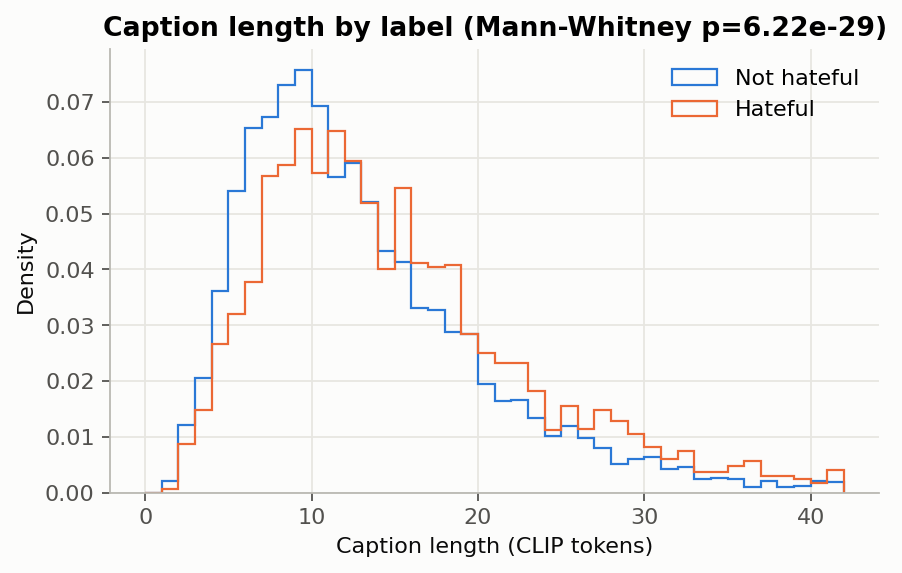

/content/drive/MyDrive/cagco_outputs/figures/eda_class_distribution.png


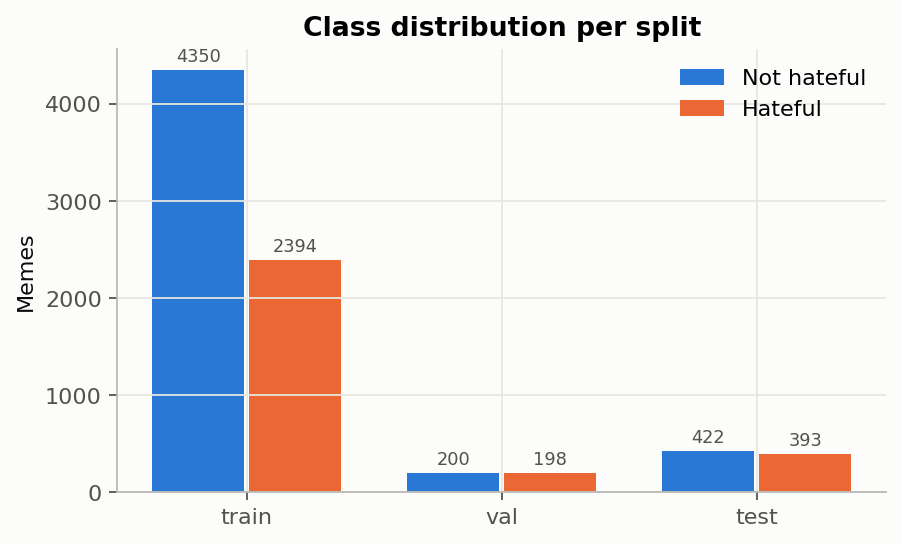

/content/drive/MyDrive/cagco_outputs/figures/eda_clip_tsne.png


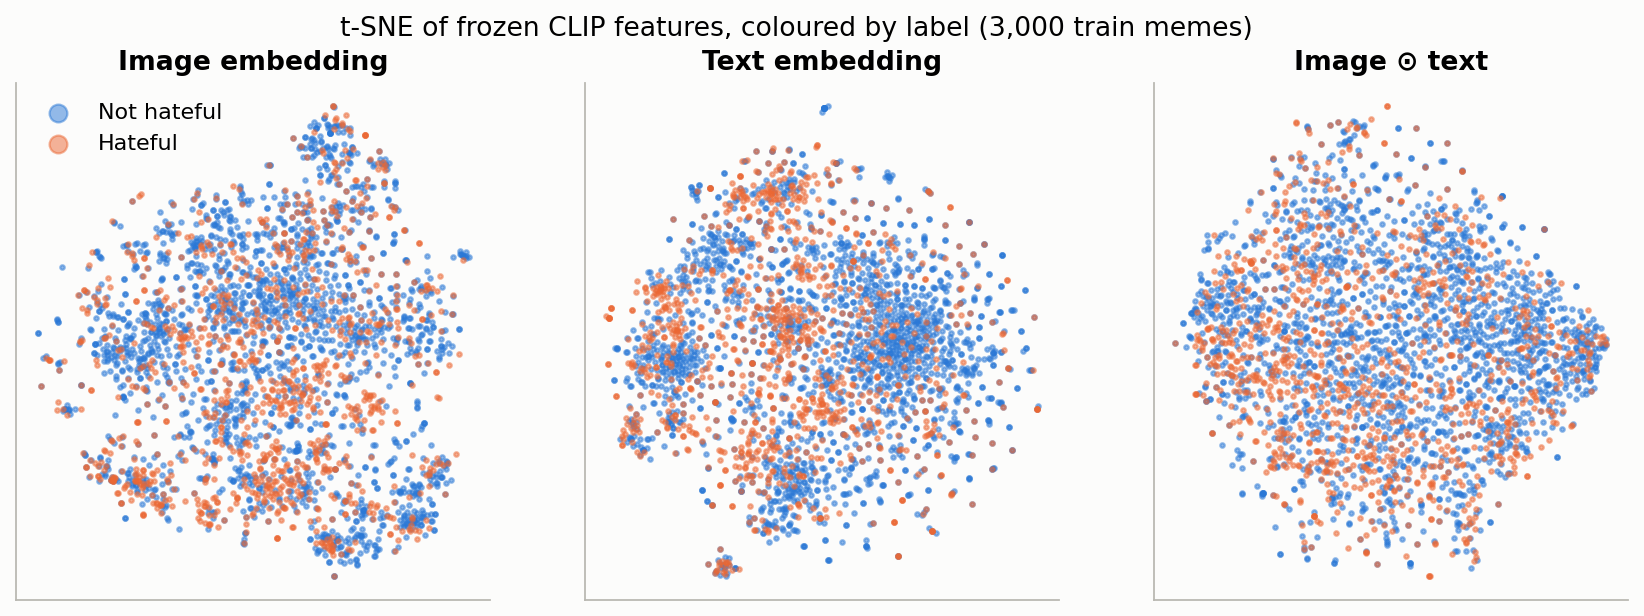

/content/drive/MyDrive/cagco_outputs/figures/eda_confounder_examples.png


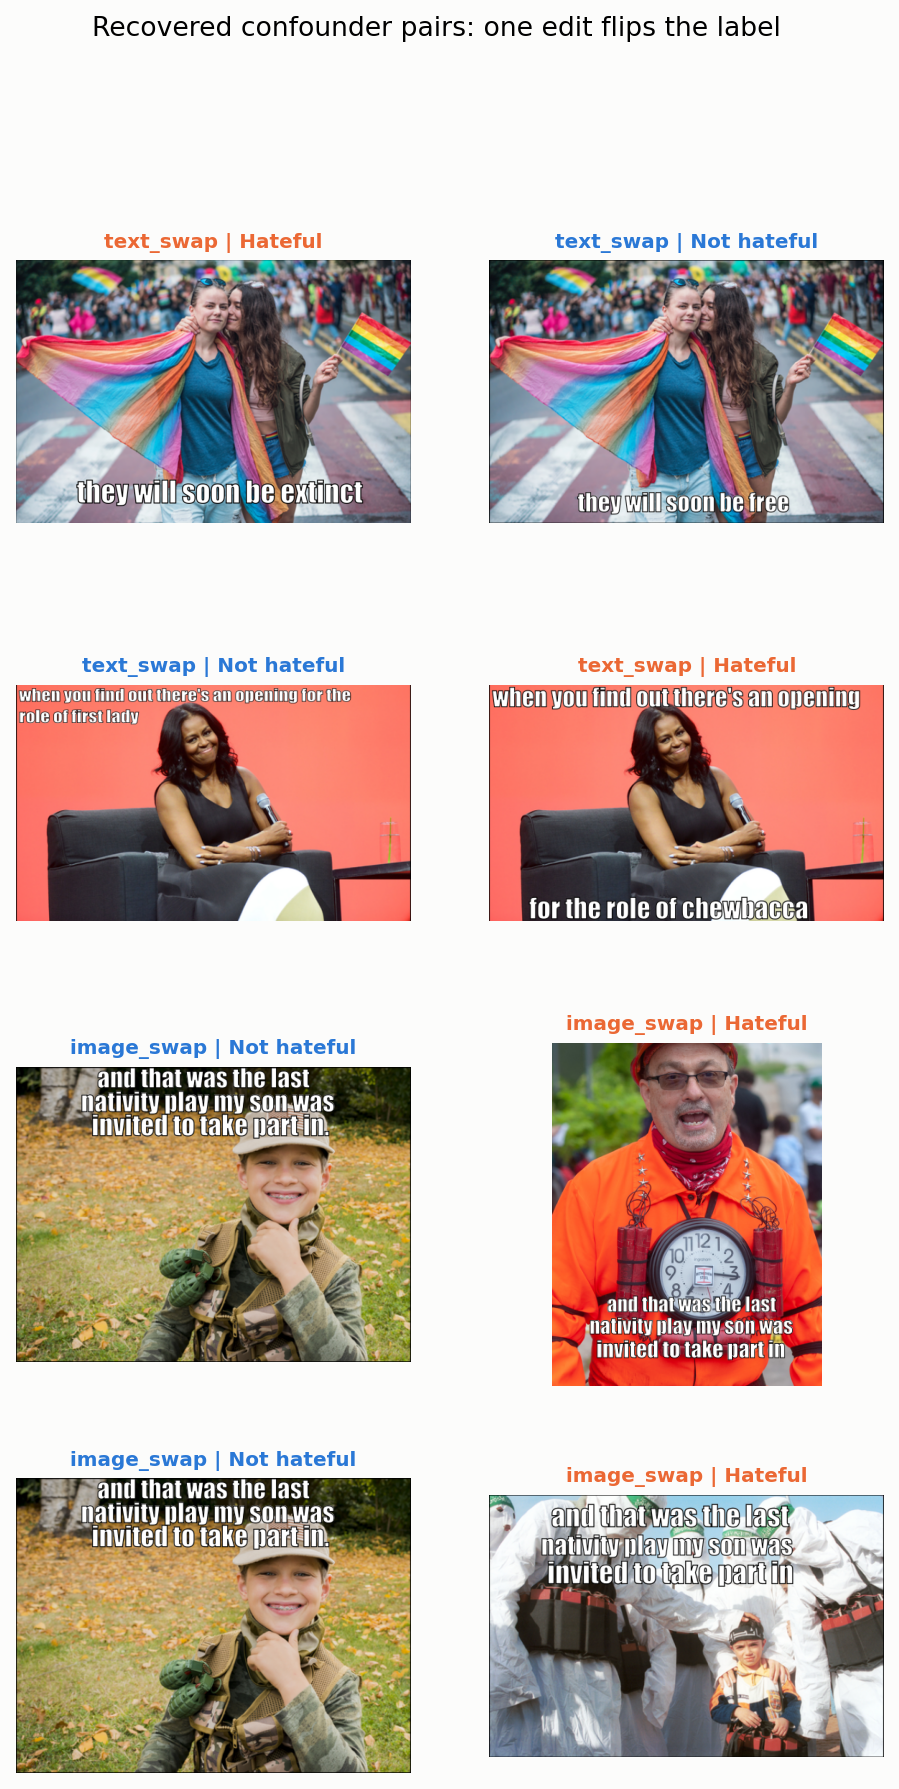

/content/drive/MyDrive/cagco_outputs/figures/eda_image_properties.png


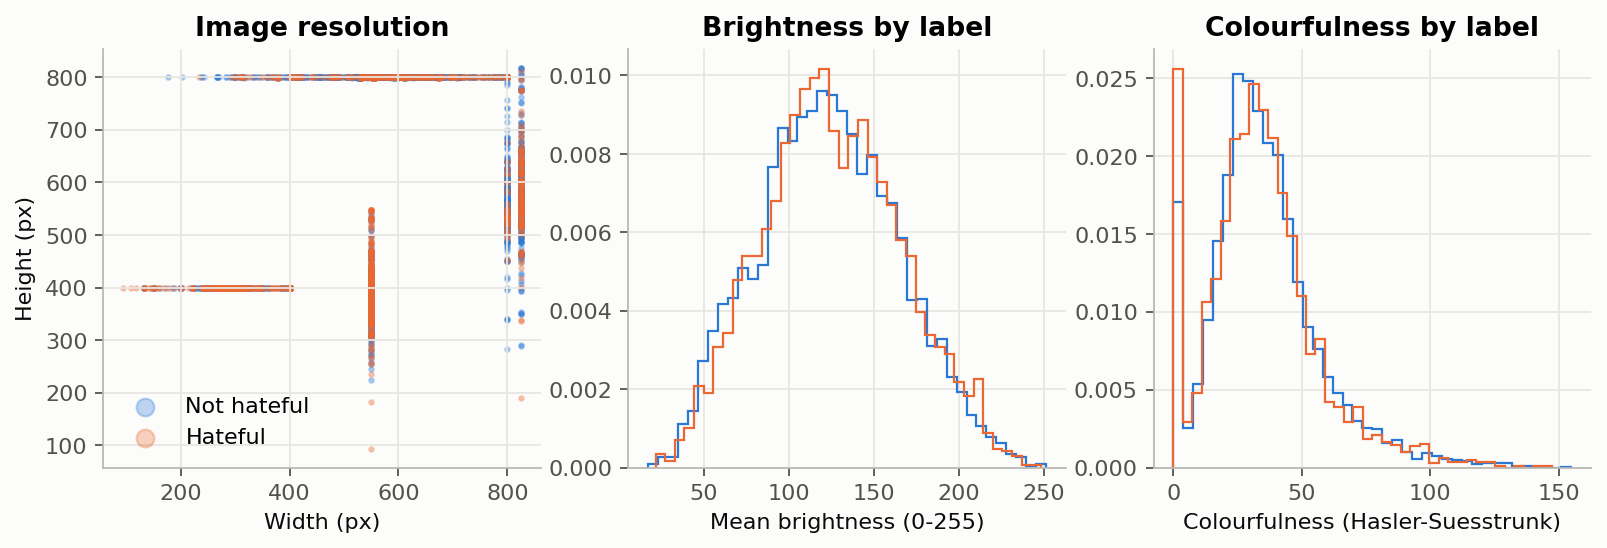

/content/drive/MyDrive/cagco_outputs/figures/eda_lexicon_by_subcategory.png


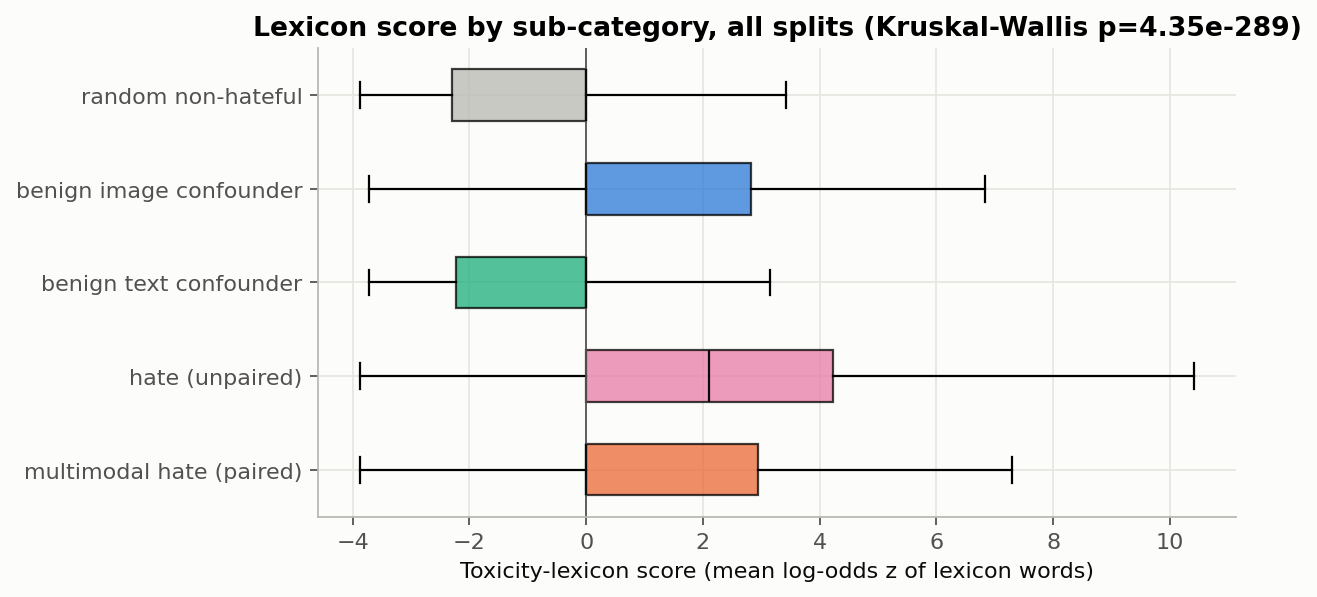

/content/drive/MyDrive/cagco_outputs/figures/eda_log_odds_words.png


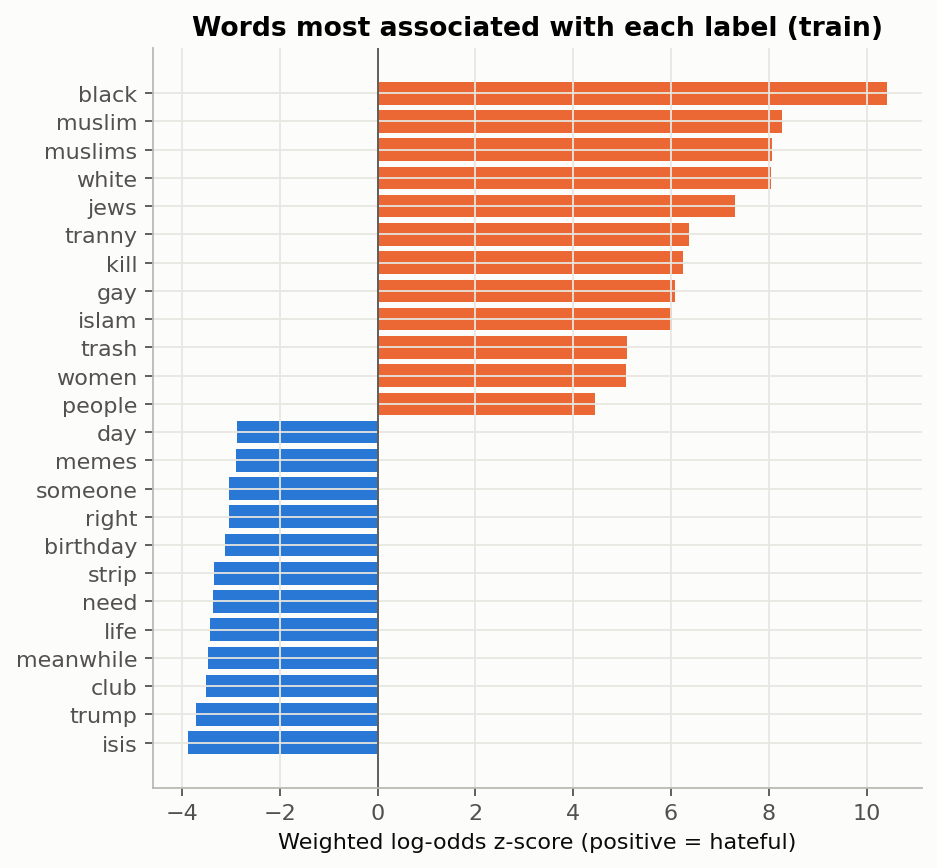

/content/drive/MyDrive/cagco_outputs/figures/eda_subcategories_by_split.png


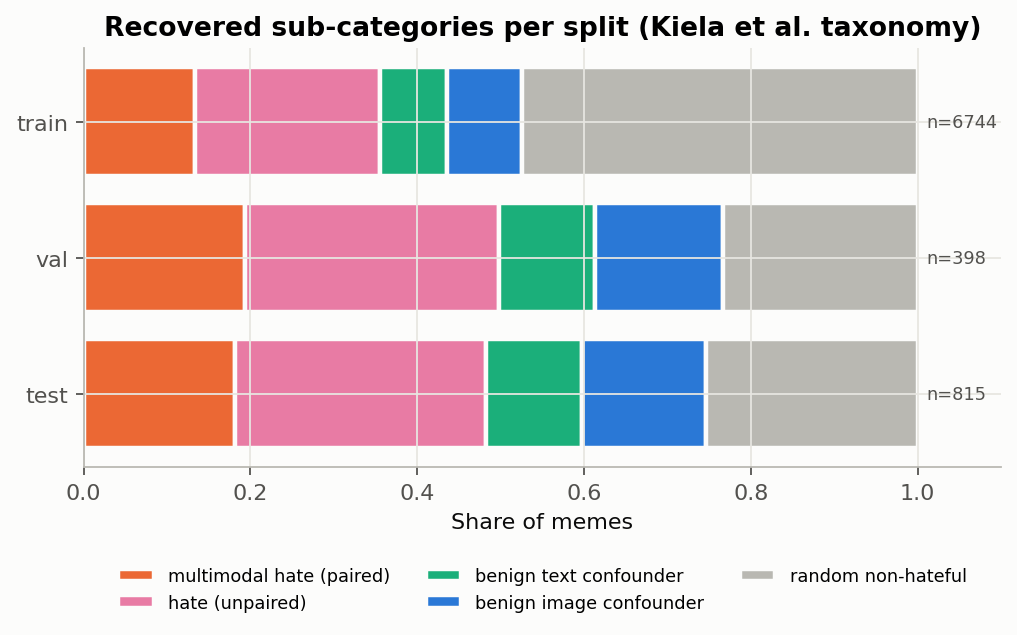

/content/drive/MyDrive/cagco_outputs/figures/res_attention.png


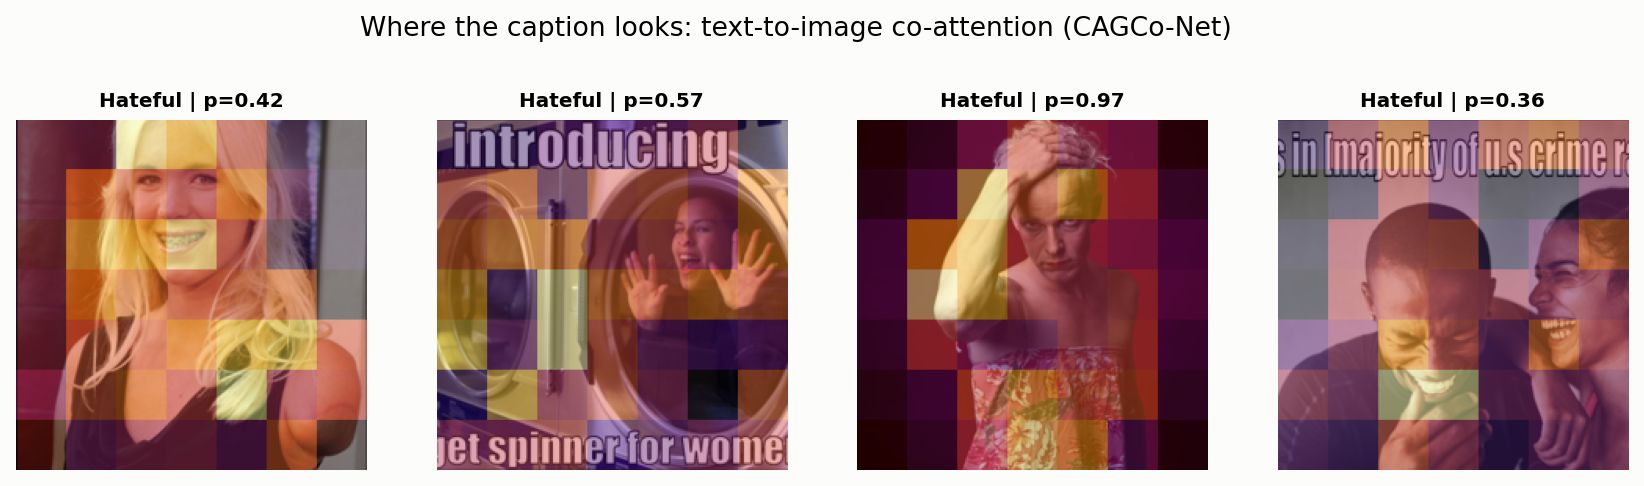

/content/drive/MyDrive/cagco_outputs/figures/res_auroc_ci.png


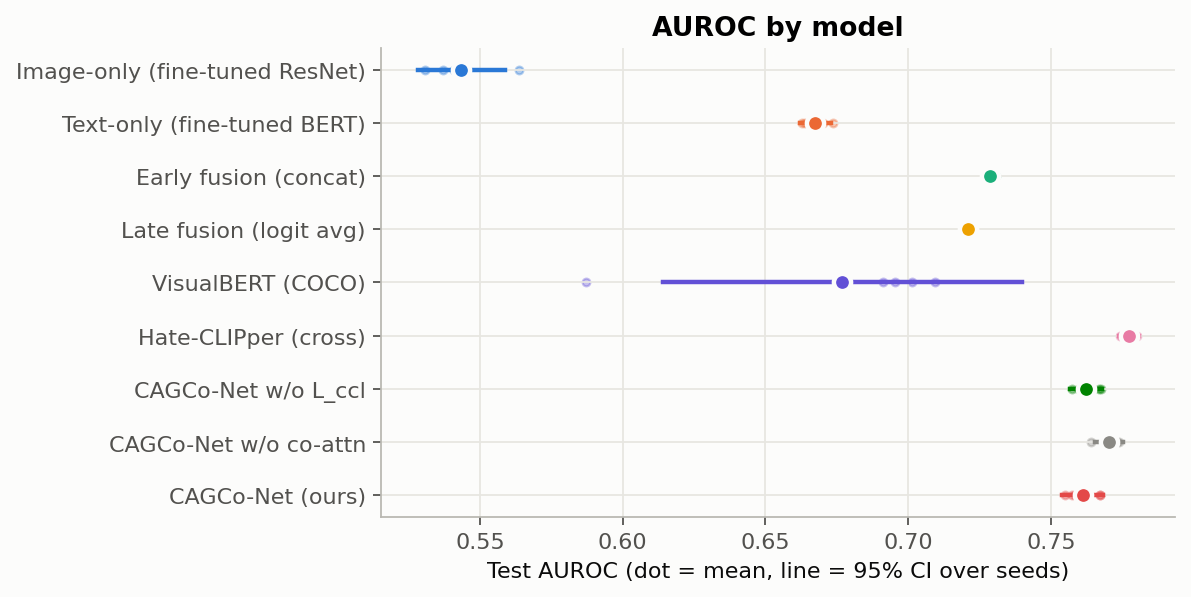

/content/drive/MyDrive/cagco_outputs/figures/res_bootstrap.png


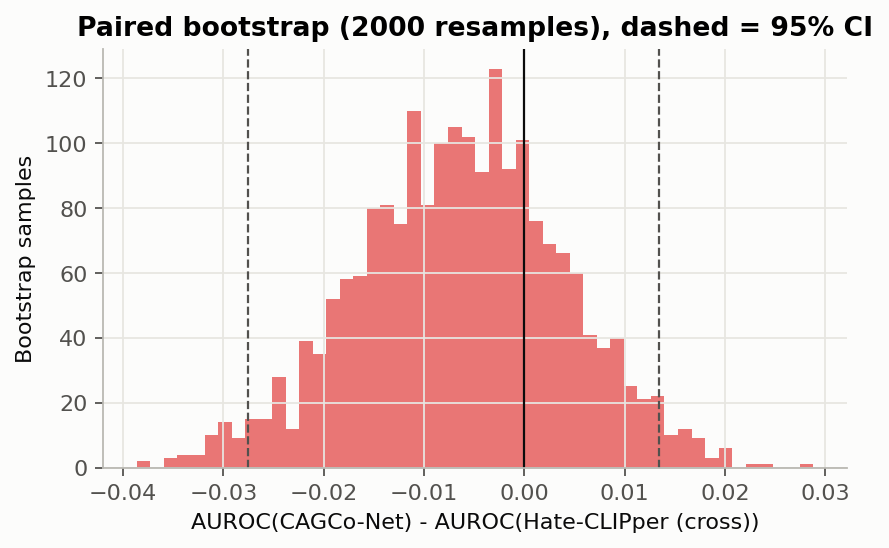

/content/drive/MyDrive/cagco_outputs/figures/res_category_accuracy.png


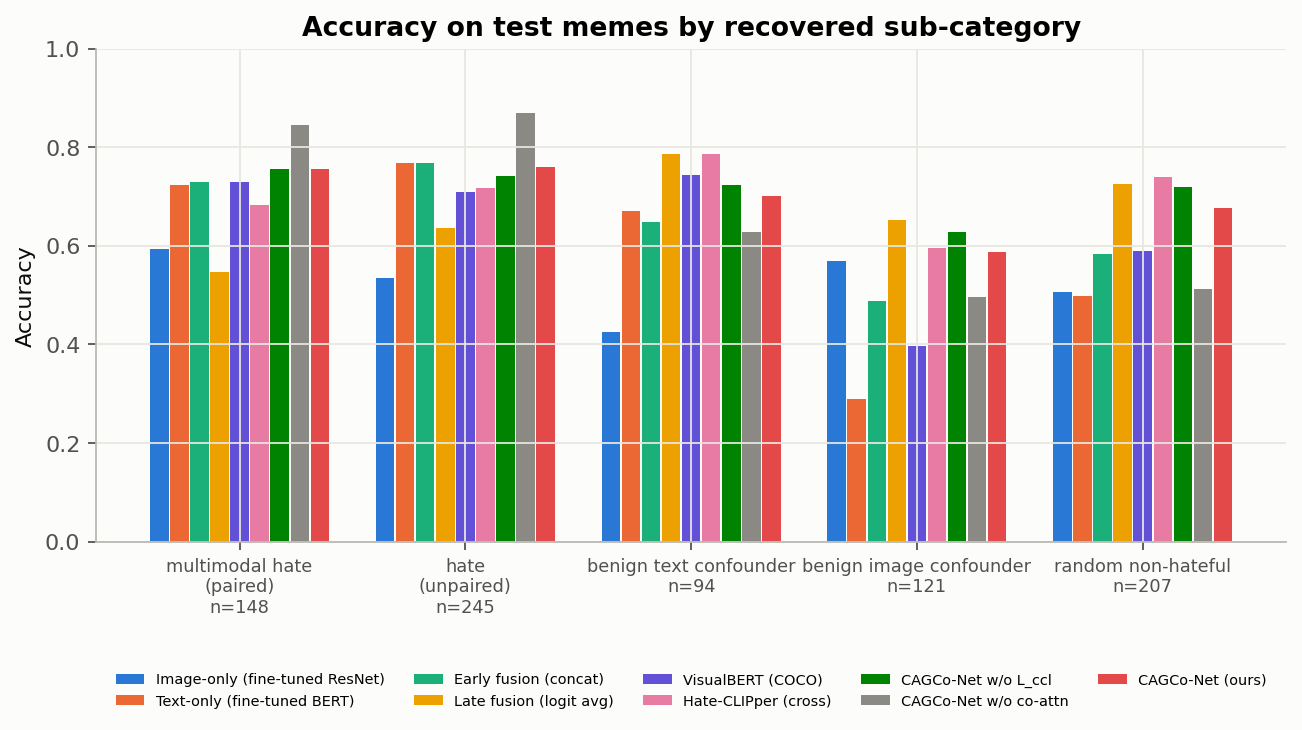

/content/drive/MyDrive/cagco_outputs/figures/res_confusion.png


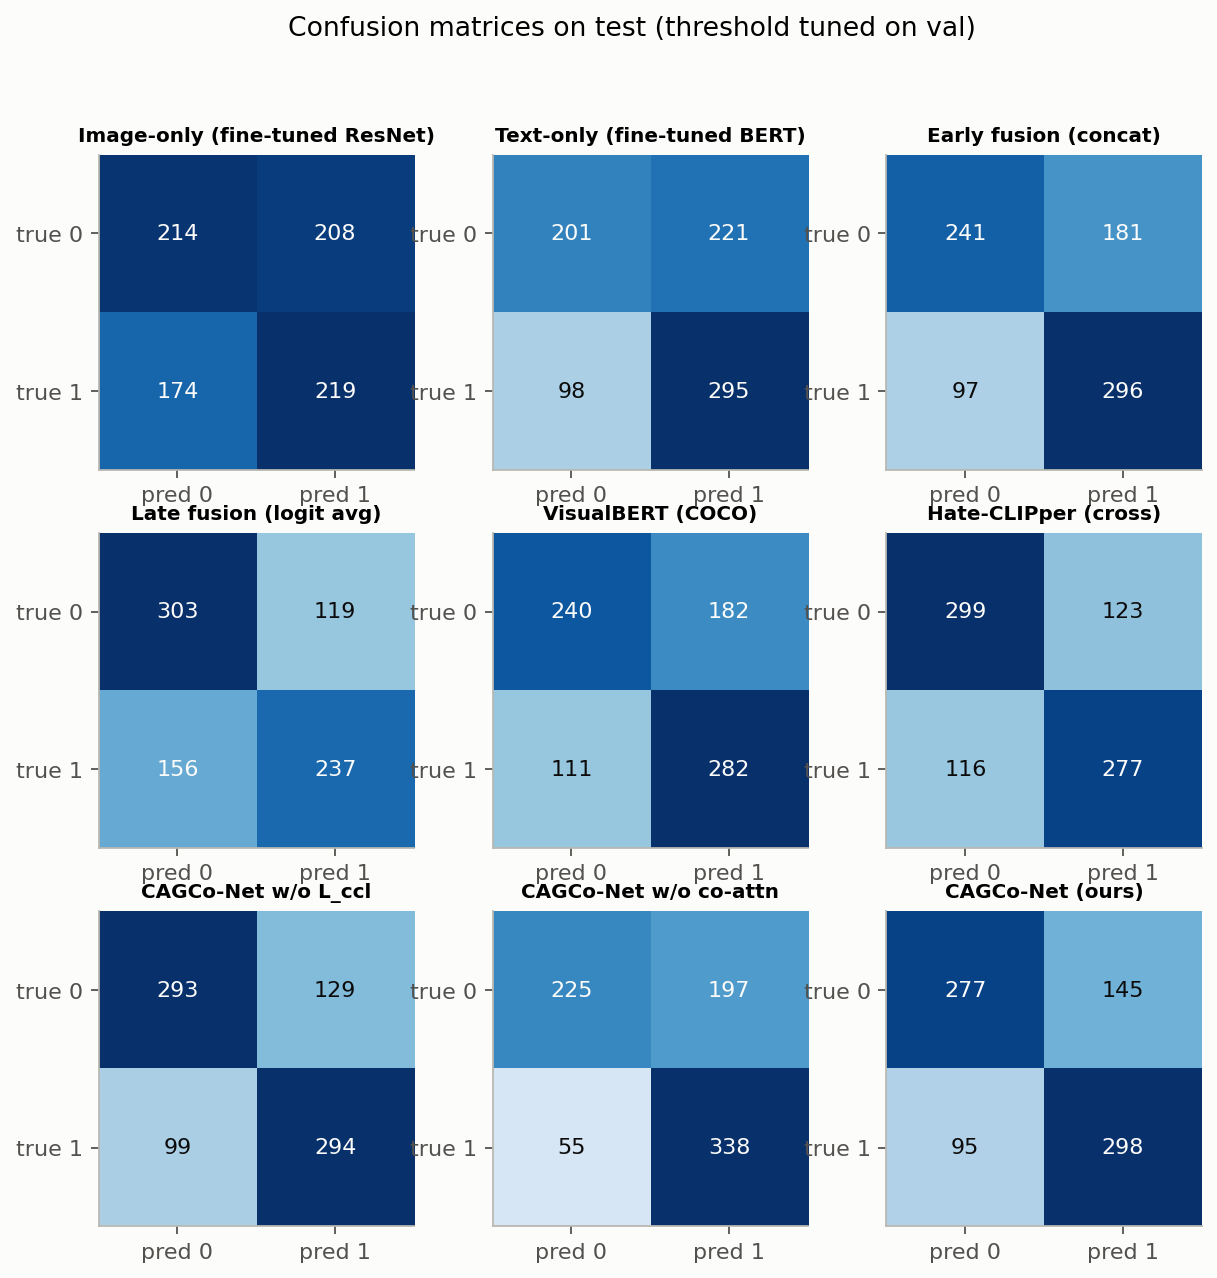

/content/drive/MyDrive/cagco_outputs/figures/res_gate.png


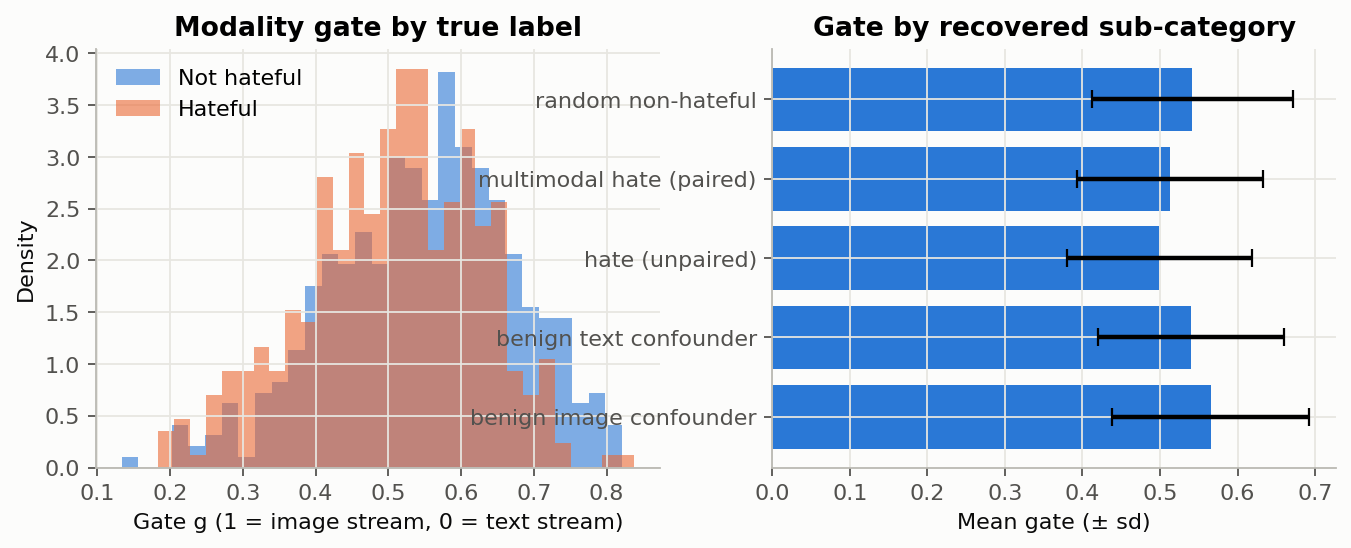

/content/drive/MyDrive/cagco_outputs/figures/res_learning_curves.png


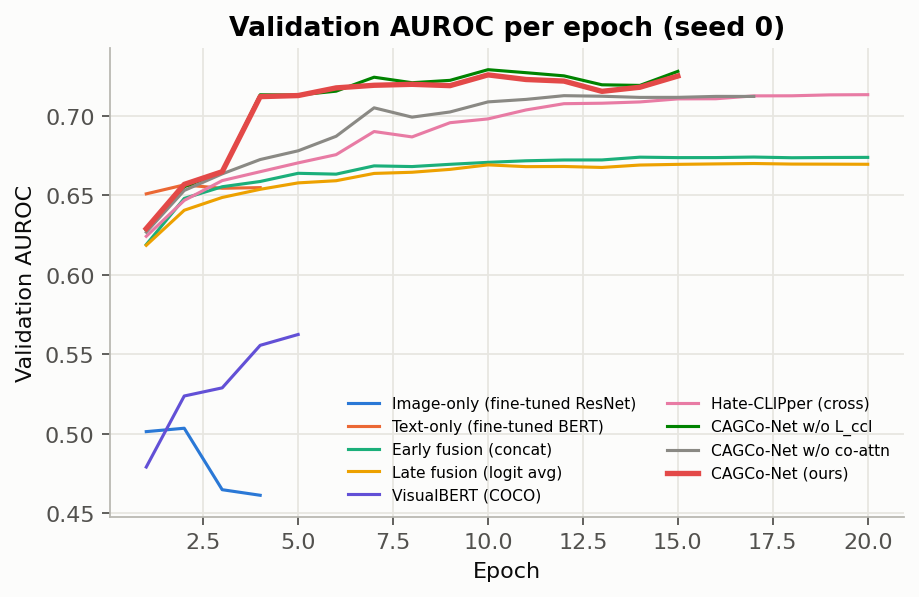

/content/drive/MyDrive/cagco_outputs/figures/res_roc.png


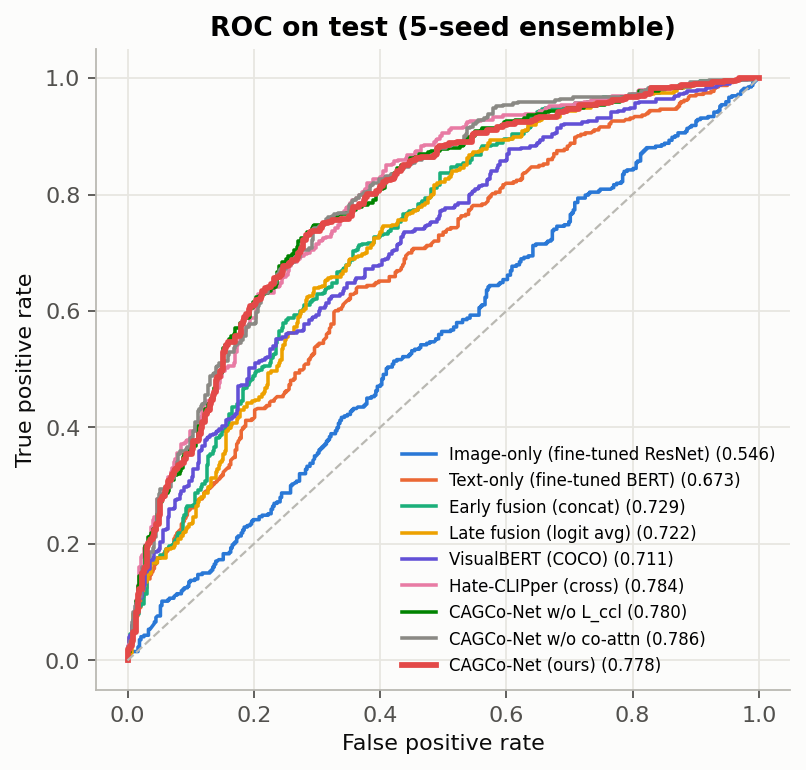

In [12]:
from IPython.display import Markdown, Image, display
display(Markdown(open(f'{OUT}/RESULTS.md').read()))
import glob
for f in sorted(glob.glob(f'{OUT}/figures/*.png')):
    print(f); display(Image(f, width=700))

In [13]:
# Save everything back to Drive
# !zip -qr /content/drive/MyDrive/cagconet_outputs.zip outputs -x 'outputs/features/*'